# Instruction Fine-Tuning a Large Language Model

Instruction fine-tuning adapts a pretrained language model to follow user instructions and answer prompts. This notebook loads the pretrained 162M parameter model, formats the Stanford Alpaca dataset, masks prompt tokens so loss is computed exclusively on responses, executes memory-efficient fine-tuning for 4 GB GPUs, and saves the final instruction-following checkpoint.

## Table of Contents
1. Imports and Memory Management Configuration
2. Stanford Alpaca Dataset Ingestion
3. Token Count Truncation to 3M Tokens
4. Alpaca Prompt Formatting Template
5. Train, Validation, and Test Partitioning
6. InstructionDataset Implementation
7. Batch Collation with Loss Target Masking
8. DataLoaders Configuration
9. Loading Pretrained 162M Checkpoint
10. Generation Utilities with Temperature and Top-k
11. Baseline Evaluation on Instruction Prompts
12. Masked Cross-Entropy Loss Functions
13. Training Loop Implementation
14. Initial Loss Evaluation
15. Fine-Tuning Execution
16. Loss Visualization
17. Qualitative Testing on Unseen Instructions
18. Checkpoint Serialization and Integrity Verification


## 1. Imports and Memory Management Configuration

Imports the required libraries and enables expandable segments (`PYTORCH_CUDA_ALLOC_CONF`) to avoid memory fragmentation on 4 GB GPUs.


In [1]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import json 
import math
import gc

import torch
import torch.nn as nn
from torch.utils.data import Dataset as TorchDataset, DataLoader

import numpy as np
import matplotlib.pyplot as plt
import tiktoken

from datasets import Dataset as HFDataset

from importlib.metadata import version


## 2. Stanford Alpaca Dataset Ingestion

Loads the Stanford Alpaca instruction-tuning dataset from local storage (`alpaca-train.arrow`).


In [3]:
dataset_candidates = [
    "../data/instruction_tuning/alpaca-train.arrow",
    "src/buildinglargelanguagemodel/data/instruction_tuning/alpaca-train.arrow",
    "/home/lakshay/BuildingLargeLanguageModel/src/buildinglargelanguagemodel/data/instruction_tuning/alpaca-train.arrow"
]
dataset_path = next(p for p in dataset_candidates if os.path.exists(p))

dataset = HFDataset.from_file(dataset_path)

print(f"Loaded dataset from: {dataset_path}")
print(f"Original dataset rows: {len(dataset):,}")
print(dataset)


Loaded dataset from: ../data/instruction_tuning/alpaca-train.arrow
Original dataset rows: 52,002
Dataset({
    features: ['instruction', 'input', 'output', 'text'],
    num_rows: 52002
})


Initializes the standard GPT-2 Byte Pair Encoding tokenizer from `tiktoken`.


In [4]:
tokenizer = tiktoken.get_encoding("gpt2")


## 3. Token Count Truncation to 3M Tokens

Truncates the dataset to approximately 3,000,000 tokens (~27,000 instruction-response pairs) for efficient fine-tuning.


In [5]:
TARGET_TOKENS = 3_000_000
running_tokens = 0
cutoff_index = 0

for i, row in enumerate(dataset):
    num_tokens = len(tokenizer.encode(row["text"], allowed_special={"<|endoftext|>"}))
    running_tokens += num_tokens
    if running_tokens >= TARGET_TOKENS:
        cutoff_index = i + 1
        break

dataset = dataset.select(range(cutoff_index))

total_character = sum(len(entry["text"]) for entry in dataset)
print(f"Truncated rows   : {len(dataset):,}")
print(f"Total characters : {total_character:,}")
print(f"Total tokens     : {running_tokens:,}")


Truncated rows   : 27,054
Total characters : 13,988,748
Total tokens     : 3,000,023


Inspects a sample instruction and target response pair from the dataset.


In [6]:
print("First sample instruction and response:\n")
print(dataset[0]["text"])

First sample instruction and response:

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Give three tips for staying healthy.

### Response:
1.Eat a balanced diet and make sure to include plenty of fruits and vegetables. 
2. Exercise regularly to keep your body active and strong. 
3. Get enough sleep and maintain a consistent sleep schedule.


## 4. Alpaca Prompt Formatting Template

Defines the standard Alpaca prompt template formatting user instructions and optional inputs into structured prompts ending with `### Response:`.


In [7]:
def format_input(entry):

    instruction_text = (

        f"Below is an instruction that describes a task : "
        f"Write a response that appropriately completes the request"
        f"\n\n### Instruction: \n {entry['instruction']}"
    )

    input_text = f"\n\n### Input:\n{entry['input']}" if entry ["input"] else ""

    return instruction_text + input_text

Formats sample instructions with and without additional input context to verify prompt structure.


In [8]:
format_input(dataset[50])

'Below is an instruction that describes a task : Write a response that appropriately completes the request\n\n### Instruction: \n Edit the following sentence to make it more concise.\n\n### Input:\nHe ran to the bus stop in order to catch the bus that was due to arrive in five minutes.'

In [ ]:
model_input = format_input(dataset[999])

desired_responses = f"\n\n### Response\n{dataset[999]['output']}"

print(model_input + desired_responses)

## 5. Train, Validation, and Test Partitioning

Splits the 3M-token dataset into 85% training, 10% test, and 5% validation subsets.


In [10]:
num_samples = len(dataset)
train_portion = int(num_samples * 0.85)
test_portion = int(num_samples * 0.10)
val_portion = num_samples - train_portion - test_portion

train_data = dataset.select(range(train_portion))
test_data = dataset.select(range(train_portion, train_portion + test_portion))
val_data = dataset.select(range(train_portion + test_portion, num_samples))


Displays sample counts across the training, validation, and test subsets.


In [11]:
print(f"Training set length  : {len(train_data):,}")
print(f"Validation set length: {len(val_data):,}")
print(f"Test set length      : {len(test_data):,}")


Training set length  : 22,995
Validation set length: 1,354
Test set length      : 2,705


## 6. InstructionDataset Implementation

Implements `InstructionDataset` (inheriting from `torch.utils.data.Dataset`), tokenizing each prompt-response pair with the BPE tokenizer.


In [ ]:
class InstructionDataset(TorchDataset):
    def __init__(self, data, tokenizer):
        self.data = data
        
        self.encoded_texts = []
        for entry in data:
            instruction_plus_input = format_input(entry)
            response_text = f"\n\n### Response:\n{entry['output']}"
            full_text = instruction_plus_input + response_text
            self.encoded_texts.append(
                tokenizer.encode(full_text)
            )

    def __getitem__(self, index):
        return self.encoded_texts[index]

    def __len__(self):
        return len(self.data)

## 7. Batch Collation with Loss Target Masking

Implements `custom_collate_fn` to pad batches, clamp sequence lengths to 256 tokens, and mask prompt tokens with `-100` so loss is computed exclusively on responses.


In [13]:
def custom_collate_fn(
    batch,
    pad_token_id=50256,
    ignore_index=-100,
    allowed_max_length=256,
    device="cpu"
):
    batch_max_length = max(len(item) + 1 for item in batch)
    inputs_lst, targets_lst = [], []

    for item in batch:
        new_item = item.copy()
        new_item += [pad_token_id]
        
        padded = (
            new_item + [pad_token_id] *
            (batch_max_length - len(new_item))
        )
        inputs = torch.tensor(padded[:-1]) 
        targets = torch.tensor(padded[1:])  

        mask = targets == pad_token_id
        indices = torch.nonzero(mask).squeeze()
        
        if indices.numel() > 1:
            targets[indices[1:]] = ignore_index

        if allowed_max_length is not None:
            inputs = inputs[:allowed_max_length]
            targets = targets[:allowed_max_length]

        inputs_lst.append(inputs)
        targets_lst.append(targets)

    inputs_tensor = torch.stack(inputs_lst).to(device)
    targets_tensor = torch.stack(targets_lst).to(device)
    return inputs_tensor, targets_tensor


Tests `custom_collate_fn` on a mock batch to confirm target masking behavior.


In [14]:
input_1 = [0, 1, 2, 3, 4]
input_2 = [5, 6]
input_3 = [7, 8, 9]

batch = (
    input_1,
    input_2,
    input_3
)

input_tensor, target_tensor = custom_collate_fn(batch)

In [15]:
input_tensor 

tensor([[    0,     1,     2,     3,     4],
        [    5,     6, 50256, 50256, 50256],
        [    7,     8,     9, 50256, 50256]])

In [16]:
target_tensor 

tensor([[    1,     2,     3,     4, 50256],
        [    6, 50256,  -100,  -100,  -100],
        [    8,     9, 50256,  -100,  -100]])

## 8. DataLoaders Configuration

Creates DataLoaders with a batch size of 2 to fit within the 4 GB VRAM limit of the GTX 1650 GPU.


In [17]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [ ]:
from functools import partial 

customized_collate_fn = partial(
    custom_collate_fn,
    device = device,
    allowed_max_length = 256
)

In [ ]:
num_workers = 0
batch_size = 2

torch.manual_seed(123)

train_dataset = InstructionDataset(train_data, tokenizer)
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    collate_fn=customized_collate_fn,
    shuffle=True,
    drop_last=True,
    num_workers=num_workers
)


In [20]:
val_dataset = InstructionDataset(val_data, tokenizer)
val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    collate_fn=customized_collate_fn,
    shuffle=False,
    drop_last=False,
    num_workers=num_workers
)

test_dataset = InstructionDataset(test_data, tokenizer)
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    collate_fn=customized_collate_fn,
    shuffle=False,
    drop_last=False,
    num_workers=num_workers
)

Inspects a sample batch from the training loader to verify tensor dimensions and device placement.


In [21]:
print("Train loader sample batch:")
for inputs, targets in train_loader:
    print("Inputs shape:", inputs.shape, "Targets shape:", targets.shape)
    break


Train loader sample batch:
Inputs shape: torch.Size([2, 69]) Targets shape: torch.Size([2, 69])


## 9. Loading Pretrained 162M Checkpoint

Dynamically loads `GPTModel`, defines the 162M parameter configuration matching our pretrained checkpoint, and loads weights from `3M_Model/model.pth`.


In [ ]:
import os
import json
import torch

def import_from_ipynb(nb_path, *names):
    candidates = [
        nb_path,
        os.path.join(os.path.dirname(__file__) if "__file__" in locals() else ".", nb_path),
        os.path.abspath(f"src/buildinglargelanguagemodel/LLM/{nb_path}"),
        f"/home/lakshay/BuildingLargeLanguageModel/src/buildinglargelanguagemodel/LLM/{nb_path}"
    ]
    resolved_path = next((p for p in candidates if os.path.exists(p)), None)
    if not resolved_path:
        raise FileNotFoundError(f"Could not find {nb_path}.")

    with open(resolved_path, "r", encoding="utf-8") as f:
        nb_data = json.load(f)

    skip_signatures = [
        "logits = model(batch)",
        "start_context =",
        "layer_sizes =",
        "batch = torch.tensor",
        "out_ffn = ffn(",
        "out_att = att(",
        "out_block = block(",
        "ln_out = ln(",
        "y_gelu = gelu(x)",
        "total_params = sum("
    ]

    code_blocks = []
    for cell in nb_data.get("cells", []):
        if cell.get("cell_type") == "code":
            src = "".join(cell.get("source", []))
            if any(sig in src for sig in skip_signatures):
                continue
            code_blocks.append(src)

    exec_scope = {}
    exec("\n\n".join(code_blocks), exec_scope)
    return [exec_scope[name] for name in names]

GPTModel, generate_text_simple = import_from_ipynb("llm_architecture.ipynb", "GPTModel", "generate_text_simple")


BASE_CONFIG = {
    "vocab_size": 50257,    
    "context_length": 256,   
    "emb_dim": 768,          
    "n_heads": 12,           
    "n_layers": 12,          
    "drop_rate": 0.0,        
    "qkv_bias": False       
}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

model = GPTModel(BASE_CONFIG)

checkpoint_candidates = [
    "../3M_Model/model.pth",
    "src/buildinglargelanguagemodel/3M_Model/model.pth",
    "/home/lakshay/BuildingLargeLanguageModel/src/buildinglargelanguagemodel/3M_Model/model.pth"
]
checkpoint_path = next(p for p in checkpoint_candidates if os.path.exists(p))

model.load_state_dict(torch.load(checkpoint_path, map_location=device, weights_only=True))
model.to(device)
model.eval()

print(f"Successfully loaded 3M model weights from: {checkpoint_path}")
print(f"Total model parameters: {sum(p.numel() for p in model.parameters()):,}")


Successfully imported CausalMultiHeadSelfAttention from: /home/lakshay/BuildingLargeLanguageModel/src/buildinglargelanguagemodel/Attention/multihead_self_attention.ipynb
Using device: cuda
Successfully loaded 3M model weights from: ../3M_Model/model.pth
Total model parameters: 162,419,712


## 10. Generation Utilities with Temperature and Top-k

Implements device-safe `generate` along with `text_to_token_ids` and `token_ids_to_text`, supporting temperature scaling and top-k filtering.


In [ ]:
def generate(model, idx, max_new_tokens, context_size, temperature=0.0, top_k=None, eos_id=None):
    # Ensure input tensor is on the same device as model
    device = next(model.parameters()).device
    idx = idx.to(device)

    for _ in range(max_new_tokens):
        idx_cond = idx[:, -context_size:]
        with torch.no_grad():
            logits = model(idx_cond)
        logits = logits[:, -1, :]

        if top_k is not None:
            top_logits, _ = torch.topk(logits, top_k)
            min_val = top_logits[:, -1]
            logits = torch.where(logits < min_val, torch.tensor(float("-inf"), device=logits.device), logits)

        if temperature > 0.0:
            logits = logits / temperature
            logits = logits - logits.max(dim=-1, keepdim=True).values            
            probs = torch.softmax(logits, dim=-1) 
            idx_next = torch.multinomial(probs, num_samples=1)  
        else:
            idx_next = torch.argmax(logits, dim=-1, keepdim=True)  

        if eos_id is not None and (idx_next == eos_id).all():  
            break

        idx = torch.cat((idx, idx_next), dim=1)

    return idx

In [24]:
def text_to_token_ids(text, tokenizer):

    encoded = tokenizer.encode(text, allowed_special = {"<|endoftext|>"})
    encoded_tensor = torch.tensor(encoded).unsqueeze(0)

    return encoded_tensor

In [25]:
def token_ids_to_text(token_ids , tokenizer):

    flat = token_ids.squeeze(0)

    return tokenizer.decode(flat.tolist())

## 11. Baseline Evaluation on Instruction Prompts

Generates a response from the model before fine-tuning to observe baseline continuation behavior.


In [26]:
torch.manual_seed(123)

input_text = format_input(val_data[0])
print(input_text)

Below is an instruction that describes a task : Write a response that appropriately completes the request

### Instruction: 
 Change this sentence to the future tense: "I am eating a pizza."


In [27]:
token_ids = generate(
    model=model,
    idx=text_to_token_ids(input_text, tokenizer).to(device),
    max_new_tokens=35,
    context_size=BASE_CONFIG["context_length"],
    eos_id=50256,
)
generated_text = token_ids_to_text(token_ids, tokenizer)


In [28]:
response_text = (
    generated_text[len(input_text):]
    .replace("### Response:", "")
    .strip()
)
print(response_text)

installedselected selector Rug pinsspeaking extremists Gaga 22 outsourcing AzerbaiecauseAugust275illy strife Hailare beetfortuneliviousullivan Mildodd reconcile textbooks1111 sole repaired cra gaze amounted frantic familiarityÃÂÃÂÃÂÃÂ


## 12. Masked Cross-Entropy Loss Functions

Defines `calc_loss_batch` and `calc_loss_loader`, computing cross-entropy loss exclusively on target response tokens by ignoring `-100` indices.


In [ ]:
def calc_loss_batch(input_batch, target_batch, model, device):
    input_batch, target_batch = input_batch.to(device), target_batch.to(device)
    
    # Ensure input sequence length does not exceed model context length (256)
    context_length = getattr(model, "context_length", 256)
    if input_batch.shape[1] > context_length:
        input_batch = input_batch[:, :context_length]
        target_batch = target_batch[:, :context_length]

    logits = model(input_batch)
    loss = torch.nn.functional.cross_entropy(logits.flatten(0, 1), target_batch.flatten())
    return loss


def calc_loss_loader(data_loader, model, device, num_batches=None):
    total_loss = 0.

    if len(data_loader) == 0:
        return float("nan")
    elif num_batches is None:
        num_batches = len(data_loader)
    else:
        num_batches = min(num_batches, len(data_loader))

    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i < num_batches:
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            total_loss += loss.item()
        else:
            break
        
    return total_loss / num_batches

## 13. Training Loop Implementation

Implements `train_model_simple` and `evaluate_model` to train the model, track losses, and periodically print sample generations.


In [30]:
def train_model_simple(model, train_loader, val_loader, optimizer, device, num_epochs,
                       eval_freq, eval_iter, start_context, tokenizer):
    
    train_losses, val_losses, track_tokens_seen = [], [], []
    tokens_seen, global_step = 0, -1


    for epoch in range(num_epochs):
        model.train()  
        
        for input_batch, target_batch in train_loader:
            optimizer.zero_grad() 
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            loss.backward() 
            optimizer.step() 
            tokens_seen += input_batch.numel()
            global_step += 1

            
            if global_step % eval_freq == 0:
                train_loss, val_loss = evaluate_model(
                    model, train_loader, val_loader, device, eval_iter)
                train_losses.append(train_loss)
                val_losses.append(val_loss)
                track_tokens_seen.append(tokens_seen)
                print(f"Ep {epoch+1} (Step {global_step:06d}): "
                      f"Train loss {train_loss:.3f}, Val loss {val_loss:.3f}")

       
        generate_and_print_sample(
            model, tokenizer, device, start_context
        )

    return train_losses, val_losses, track_tokens_seen

def evaluate_model(model, train_loader, val_loader, device, eval_iter):
    model.eval()
    with torch.no_grad():
        train_loss = calc_loss_loader(train_loader, model, device, num_batches=eval_iter)
        val_loss = calc_loss_loader(val_loader, model, device, num_batches=eval_iter)
    model.train()
    return train_loss, val_loss


def generate_and_print_sample(model, tokenizer, device, start_context):
    model.eval()
    context_size = model.pos_emb.weight.shape[0]
    encoded = text_to_token_ids(start_context, tokenizer).to(device)
    with torch.no_grad():
        token_ids = generate_text_simple(
            model=model, idx=encoded,
            max_new_tokens=50, context_size=context_size
        )
    decoded_text = token_ids_to_text(token_ids, tokenizer)
    print(decoded_text.replace("\n", " ")) 
    model.train()

## 14. Initial Loss Evaluation

Computes baseline training and validation loss before fine-tuning begins.


In [31]:
model.to(device)

torch.manual_seed(123)

with torch.no_grad():
    train_loss = calc_loss_loader(train_loader, model, device, num_batches=5)
    val_loss = calc_loss_loader(val_loader, model, device, num_batches=5)

print("Training loss:", train_loss)
print("Validation loss:", val_loss)

Training loss: 10.926959991455078
Validation loss: 10.928613471984864


## 15. Fine-Tuning Execution

Executes instruction fine-tuning on the dataset for 1 epoch using the AdamW optimizer (`lr=5e-5`, `weight_decay=0.1`).


In [32]:
import time
import gc

gc.collect()
torch.cuda.empty_cache()

start_time = time.time()

torch.manual_seed(123)

optimizer = torch.optim.AdamW(model.parameters(), lr=0.00005, weight_decay=0.1)

num_epochs = 1

train_losses, val_losses, tokens_seen = train_model_simple(
    model, train_loader, val_loader, optimizer, device,
    num_epochs=num_epochs, eval_freq=5, eval_iter=5,
    start_context=format_input(val_data[0]), tokenizer=tokenizer
)

end_time = time.time()
execution_time_minutes = (end_time - start_time) / 60
print(f"Training completed in {execution_time_minutes:.2f} minutes.")


Ep 1 (Step 000000): Train loss 10.179, Val loss 10.419
Ep 1 (Step 000005): Train loss 8.003, Val loss 9.001
Ep 1 (Step 000010): Train loss 7.580, Val loss 8.218
Ep 1 (Step 000015): Train loss 7.281, Val loss 7.650
Ep 1 (Step 000020): Train loss 6.927, Val loss 7.308
Ep 1 (Step 000025): Train loss 6.540, Val loss 7.102
Ep 1 (Step 000030): Train loss 6.632, Val loss 6.946
Ep 1 (Step 000035): Train loss 5.783, Val loss 6.812
Ep 1 (Step 000040): Train loss 6.434, Val loss 6.684
Ep 1 (Step 000045): Train loss 5.355, Val loss 6.563
Ep 1 (Step 000050): Train loss 6.046, Val loss 6.459
Ep 1 (Step 000055): Train loss 5.985, Val loss 6.371
Ep 1 (Step 000060): Train loss 5.968, Val loss 6.292
Ep 1 (Step 000065): Train loss 5.745, Val loss 6.215
Ep 1 (Step 000070): Train loss 5.513, Val loss 6.144
Ep 1 (Step 000075): Train loss 5.590, Val loss 6.092
Ep 1 (Step 000080): Train loss 4.828, Val loss 6.042
Ep 1 (Step 000085): Train loss 4.863, Val loss 5.989
Ep 1 (Step 000090): Train loss 5.559, Val lo

## 16. Loss Visualization

Plots training and validation loss curves across training steps to assess convergence.


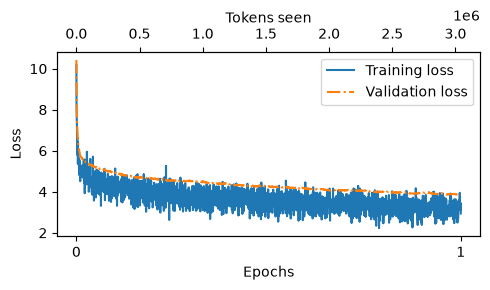

In [33]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator


def plot_losses(epochs_seen, tokens_seen, train_losses, val_losses):
    fig, ax1 = plt.subplots(figsize=(5, 3))

    ax1.plot(epochs_seen, train_losses, label="Training loss")
    ax1.plot(epochs_seen, val_losses, linestyle="-.", label="Validation loss")
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Loss")
    ax1.legend(loc="upper right")
    ax1.xaxis.set_major_locator(MaxNLocator(integer=True))  
    ax2 = ax1.twiny()  
    ax2.plot(tokens_seen, train_losses, alpha=0)  
    ax2.set_xlabel("Tokens seen")

    fig.tight_layout()  
    plt.savefig("loss-plot.pdf")
    plt.show()

epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))
plot_losses(epochs_tensor, tokens_seen, train_losses, val_losses)

## 17. Qualitative Testing on Unseen Instructions

Generates responses for unseen test set instructions and compares model outputs against ground-truth answers.


In [ ]:
torch.manual_seed(123)

for entry in test_data.select(range(3)):

    input_text = format_input(entry)

    token_ids = generate(
        model=model,
        idx=text_to_token_ids(input_text, tokenizer).to(device),
        max_new_tokens=256,
        context_size=BASE_CONFIG["context_length"],
        eos_id=50256
    )
    generated_text = token_ids_to_text(token_ids, tokenizer)
    response_text = (
        generated_text[len(input_text):]
        .replace("### Response:", "")
        .strip()
    )

    print(input_text)
    print(f"\nCorrect response:\n>> {entry['output']}")
    print(f"\nModel response:\n>> {response_text.strip()}")
    print("-------------------------------------")

## 18. Checkpoint Serialization and Integrity Verification

Saves the fine-tuned model state dictionary (`instruction_model.pth`), full optimizer checkpoint (`instruction_checkpoint.pth`), and configuration (`config.json`).


In [ ]:
import os
import json

if os.path.basename(os.getcwd()) == "LLM":
    target_dir = "../instruction_model"
else:
    target_dir = "src/buildinglargelanguagemodel/instruction_model"

os.makedirs(target_dir, exist_ok=True)

weights_path = os.path.join(target_dir, "instruction_model.pth")
torch.save(model.state_dict(), weights_path)
print(f"Saved fine-tuned weights to: {weights_path}")

checkpoint_path = os.path.join(target_dir, "instruction_checkpoint.pth")
torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "config": BASE_CONFIG
}, checkpoint_path)
print(f"Saved complete checkpoint to: {checkpoint_path}")

config_path = os.path.join(target_dir, "config.json")
with open(config_path, "w", encoding="utf-8") as f:
    json.dump(BASE_CONFIG, f, indent=4)
print(f"Saved architecture config to: {config_path}")


Saved fine-tuned weights to: ../instruction_model/instruction_model.pth
Saved complete checkpoint to: ../instruction_model/instruction_checkpoint.pth
Saved architecture config to: ../instruction_model/config.json


Reloads the saved checkpoint on CPU to verify that weights load losslessly without extra GPU memory overhead.


In [ ]:
loaded_checkpoint = torch.load(weights_path, map_location="cpu", weights_only=True)
test_model = GPTModel(BASE_CONFIG)
test_model.load_state_dict(loaded_checkpoint)
test_model.eval()

print(f"Successfully verified that '{weights_path}' is intact and valid!")
print(f"Loaded parameters: {sum(p.numel() for p in test_model.parameters()):,}")


Successfully verified that '../instruction_model/instruction_model.pth' is intact and valid!
Loaded parameters: 162,419,712
